# Week 2 — the claims domain and EDA

You will make the plots from today's slides on **your own cohort**, and write
one short sentence under each one. That sentence is the deliverable, not the
plot.

| TODO | You make | Slide |
|---|---|---|
| 1 | Rows vs. members in each file | *Three files, joined on member_id* |
| 2 | Plan-paid on a linear and a log axis | *Look at the shape of the money first* |
| 3 | Share of spend held by the top X% | *How much spend sits with the top few?* |
| 4–5 | Prevalence, then prevalence as the line moves | *Find your prevalence before accuracy* |
| 6 | High-cost rate by group, with intervals | *Compare groups with intervals, not bars* |
| 7 | "Known on day one?" for every column | *On the day I need this prediction…* |
| 8 | Four data checks | *Run four checks before you trust a figure* |

**Run:**

```bash
pip install -r requirements-dev.txt
jupyter notebook notebooks/week-02-eda.ipynb
```

**How each TODO works**

- **Hints:** which columns and which pandas call. Not the answer.
- **What you should see:** a *range*. Your seed gives you your own cohort, so
  your numbers won't match your neighbour's. Outside the range means something
  is wrong.
- **Your conclusion:** fill in the `______`. One sentence is enough.

Each TODO cell stands on its own, so you can work them in any order.

---

## 0. Setup

In [1]:
# Given — nothing to do here.
import os
import random
import sys
import uuid
from pathlib import Path

# Notebooks have no __file__, and every script in this repo assumes the repo
# root is the working directory. Walk up until we find config.py.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config.py").exists()), None)
if ROOT is None:
    raise RuntimeError(
        f"No config.py in {Path.cwd()} or any directory above it. Run this "
        "notebook from inside your clone of the repo."
    )
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from config import HIGH_COST_THRESHOLD_USD, STUDENT_SEED


def cohort_is_current() -> bool:
    """Is the data in data/ the cohort THIS seed produces?"""
    if not (Path("data/members.csv").exists()
            and Path("data/member_summary.csv").exists()):
        return False
    random.seed(STUDENT_SEED)
    expected_first_id = str(uuid.UUID(int=random.getrandbits(128), version=4))
    on_disk = pd.read_csv("data/members.csv", nrows=1).iloc[0]["member_id"]
    return on_disk == expected_first_id


# The data is gitignored, so make it when it is missing or from another seed.
if not cohort_is_current():
    print(f"Generating the cohort for STUDENT_SEED={STUDENT_SEED} ...")
    from generate_claims_data import generate

    generate()
    print()

# procedure_code holds CPT codes. Read them as text, or "99213" becomes 99213.0.
members = pd.read_csv("data/members.csv")
claims = pd.read_csv("data/claims.csv", dtype={"procedure_code": "string"})
summary = pd.read_csv("data/member_summary.csv")

assert cohort_is_current(), "data/ does not match STUDENT_SEED — regenerate it"
print(f"STUDENT_SEED        {STUDENT_SEED}")
print(f"dollar threshold    ${HIGH_COST_THRESHOLD_USD:,}")
print(f"members / claims    {len(members):,} / {len(claims):,}")

STUDENT_SEED        3
dollar threshold    $25,000
members / claims    2,000 / 21,419


If the seed printed above is not the one you were assigned, stop and fix it
first — see *Your own cohort* in the README.

In [2]:
# Given — nothing to do here. Use these helpers; don't rewrite them.
BLUE, ORANGE = "#2a78d6", "#eb6834"      # orange = high-cost, everywhere
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e2e1dd"

sns.set_theme(context="notebook", style="whitegrid")
plt.rcParams.update({
    "axes.edgecolor": GRID,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRID,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def dollars(cents):
    """Cents -> dollars. Every money column in this dataset is in cents."""
    return cents / 100


def usd(x, _pos=None):
    """Axis-tick formatter: ax.xaxis.set_major_formatter(plt.FuncFormatter(usd))."""
    for cut, suffix in ((1e6, "M"), (1e3, "k")):
        if abs(x) >= cut:
            scaled = x / cut
            digits = 0 if scaled == int(scaled) else 1
            return f"${scaled:,.{digits}f}{suffix}"
    return f"${x:,.0f}"


def threshold_line(ax, x=None):
    """Draw the $ dollar threshold as a dashed, labelled vertical line."""
    x = HIGH_COST_THRESHOLD_USD if x is None else x
    ax.axvline(x, color=MUTED, linewidth=1.2, linestyle="--", zorder=1)
    ax.annotate(f"dollar threshold ${x:,}", xy=(x, 1),
                xycoords=("data", "axes fraction"), xytext=(4, -12),
                textcoords="offset points", color=MUTED, fontsize=9)


def wilson_interval(k, n, z=1.96):
    """
    95% interval for a rate k/n. Returns (lo, hi).

    Works on single numbers or on whole columns at once:
        table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
    """
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


def plot_rates(table, ax, title):
    """
    One row per group: a dot for the rate and a line for its 95% interval.
    The dashed line is the rate for the whole cohort.

    `table` needs columns rate, lo and hi, with the group names as its index.
    """
    y = np.arange(len(table))[::-1]
    ax.hlines(y, table["lo"], table["hi"], color=BLUE, linewidth=2)
    ax.plot(table["rate"], y, "o", color=BLUE)
    ax.axvline(summary["is_high_cost"].mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.set_yticks(y, table.index)
    ax.set(title=title, xlabel="high-cost rate (95% interval)", xlim=(0, 0.13))
    ax.set_xticks([0, 0.04, 0.08, 0.12])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))


# Plan-paid per member, in dollars. Most TODOs start from this.
paid = dollars(summary["total_plan_paid_cents"])

DEMOGRAPHIC_COLUMNS = ["age_bucket", "sex", "region"]
AGE_ORDER = ["18-29", "30-39", "40-49", "50-59", "60-64"]

print("Helpers are ready.")

Helpers are ready.


---

## 1. Why we are doing this

Three teams could act on a high-cost prediction: **care management** (who do we
call?), **reserves** (how much money do we set aside?) and **pricing** (what do
we charge next year?). You'll pick yours in Week 5.

Whichever you pick, two things are already true:

1. **High-cost members are rare.** Most members cost very little.
2. **The prediction has to be made before the spending happens.** On January 1,
   not December 31.

Every TODO below checks one of those, or checks that the data is safe to use.

---

## 2. Three files, joined on `member_id`

First, find out what one row means in each file.

In [3]:
# ---------------------------------------------------------------------------
# TODO 1 — what does one row mean?
#
# For members, claims and summary, print the number of rows and the number
# of DISTINCT member_ids. If the two differ, one row is not one member.
# Then look at a few rows of claims.
#
# Docs that will help:
#   - DataFrame.shape (or Python's len)
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html
#   - Series.nunique
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.nunique.html
#   - DataFrame.head  (tip: add .T to read wide tables)
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html
# ---------------------------------------------------------------------------

for name, df in [("members", members), ("claims", claims), ("summary", summary)]:
    print(f"{name:8}  rows={len(df):,}  distinct members={df['member_id'].nunique():,}")

print(f"\nclaims rows per member: {len(claims) / claims['member_id'].nunique():.1f}")

claims.head(3).T

members   rows=2,000  distinct members=2,000
claims    rows=21,419  distinct members=2,000
summary   rows=2,000  distinct members=2,000

claims rows per member: 10.7


,0,1,2
claim_id,781f9c58-d664-4fa9-a8a8-529f035efa25,85ef3430-ed03-4db4-9e38-378426d0b944,e0f9e038-eb8f-424f-b804-d82098418117
member_id,21636369-8b52-4b4a-97b7-50923ceb3ffd,21636369-8b52-4b4a-97b7-50923ceb3ffd,21636369-8b52-4b4a-97b7-50923ceb3ffd
claim_type,Institutional,Institutional,Institutional
service_date,2024-11-23,2024-01-16,2024-03-09
adjudication_status,approved,approved,approved
diagnosis_code,F41.1,Z00.00,M54.5
procedure_code,99232,99213,43239
billed_cents,53499,27734,311918
allowed_cents,35409,11049,171768
plan_paid_cents,24046,5649,129150


**What you should see.** `members` and `summary` have one row per member (2,000
rows, 2,000 members). `claims` has about 10–12 rows per member.

**Your conclusion**: why can't a model train on `claims.csv` as it is?

> A row in claims.csv is one claim, not one member, so each member appears about 10.7 times. To train a model, the claims have to be aggregated to one row per member first, which is what member_summary.csv does.

---

## 3. The shape of the money

`total_plan_paid_cents` is what the plan paid for a member over the year. It is
the number this whole project is about.

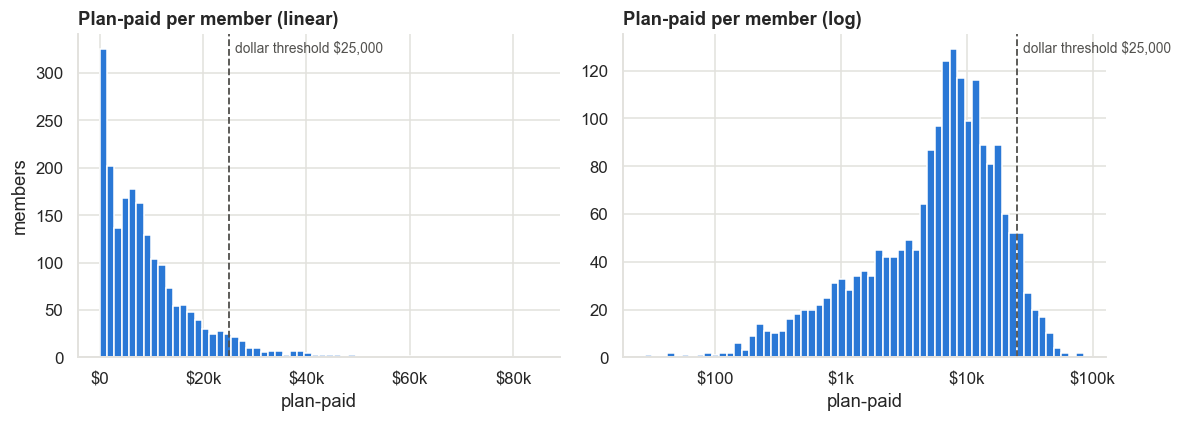

mean   $9,393
median $7,012
members at $0: 0


In [4]:
# ---------------------------------------------------------------------------
# TODO 2 — plot plan-paid per member on a linear axis, then a log axis.
#
# Two histograms side by side, with the dollar threshold on both. Then
# print the mean and the median.
#
# Given: `paid` (dollars per member) and threshold_line(ax), both in the
# helpers cell. A log axis can't show $0, so leave zeros out of that panel,
# and space the bins evenly in log terms rather than in dollars.
#
# Docs that will help:
#   - pyplot.subplots
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html
#   - Axes.hist
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html
#   - Axes.set_xscale
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xscale.html
#   - numpy.logspace
#     https://numpy.org/doc/stable/reference/generated/numpy.logspace.html
#   - Series.mean / Series.median
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.median.html
# ---------------------------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Left: linear axis
ax1.hist(paid, bins=60, color=BLUE)
threshold_line(ax1)
ax1.set(title="Plan-paid per member (linear)", xlabel="plan-paid", ylabel="members")
ax1.xaxis.set_major_formatter(plt.FuncFormatter(usd))

# Right: log axis (no zeros, bins evenly spaced on a log scale)
nonzero = paid[paid > 0]
bins = np.logspace(np.log10(nonzero.min()), np.log10(nonzero.max()), 60)
ax2.hist(nonzero, bins=bins, color=BLUE)
ax2.set_xscale("log")
threshold_line(ax2)
ax2.set(title="Plan-paid per member (log)", xlabel="plan-paid")
ax2.xaxis.set_major_formatter(plt.FuncFormatter(usd))

plt.tight_layout()
plt.show()

print(f"mean   ${paid.mean():,.0f}")
print(f"median ${paid.median():,.0f}")
print(f"members at $0: {(paid == 0).sum()}")

**What you should see.** On the linear axis, most members are squeezed to the
left and a long tail stretches to the right. On the log axis the shape is easy
to read. The mean is higher than the median (median around $6k–9k).

**Your conclusion**: which number better describes a typical member, the mean or the median? Why?

The median 7,012 dollars better describes a typical member than the mean 9,393 dollars, because a few very high-cost members pull the mean up, while the median is just the member in the middle.

### How much spend sits with the top few?

Last week: in real US healthcare, the costliest 5% of people drive about half
of all spending. Check whether your cohort looks like that.

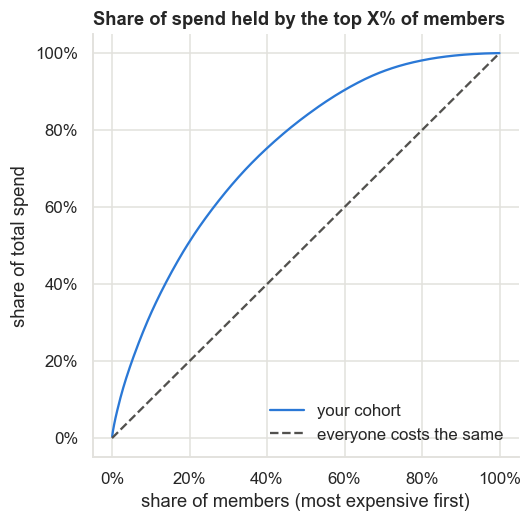

top 5% hold 19.6% of spend
top 10% hold 32.3% of spend
top 20% hold 51.0% of spend


In [5]:
# ---------------------------------------------------------------------------
# TODO 3 — share of total spend held by the top X% of members.
#
# Sort members from most to least expensive. Plot the running share of
# total spend (y) against the share of members counted so far (x). Add a
# dashed diagonal for "everyone costs the same". Then print the share
# held by the top 5%, 10% and 20%.
#
# Docs that will help:
#   - numpy.sort  (it sorts ascending; how do you reverse it?)
#     https://numpy.org/doc/stable/reference/generated/numpy.sort.html
#   - numpy.cumsum
#     https://numpy.org/doc/stable/reference/generated/numpy.cumsum.html
#   - numpy.arange
#     https://numpy.org/doc/stable/reference/generated/numpy.arange.html
#   - Axes.plot  (see the linestyle argument)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html
# ---------------------------------------------------------------------------

sorted_paid = np.sort(paid.to_numpy())[::-1]          # most expensive first
cum_share_spend = np.cumsum(sorted_paid) / sorted_paid.sum()
share_members = np.arange(1, len(sorted_paid) + 1) / len(sorted_paid)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(share_members, cum_share_spend, color=BLUE, label="your cohort")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", label="everyone costs the same")
ax.set(title="Share of spend held by the top X% of members",
       xlabel="share of members (most expensive first)",
       ylabel="share of total spend")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
plt.show()

for top in (0.05, 0.10, 0.20):
    n = int(len(sorted_paid) * top)
    print(f"top {top:.0%} hold {sorted_paid[:n].sum() / sorted_paid.sum():.1%} of spend")

**What you should see.** A curve that bows above the diagonal. The top 20% of
members hold roughly 45–52% of spend.

**Your conclusion**: your top 5% hold ___% of spend. Is that more or less than the ~50% in real life?

> My top 5% hold 19.6% of spend, which is less than the ~50% in real life. That suggests the synthetic data has a thinner tail than real healthcare, with fewer extremely expensive members (transplants, long ICU stays, specialty drugs).

---

## 4. The label is a line someone drew

`is_high_cost` is 1 when a member's plan-paid is over the **dollar threshold**
(`HIGH_COST_THRESHOLD_USD` in `config.py`, $25,000). It is a choice, not a fact
about the member.

In [6]:
# ---------------------------------------------------------------------------
# TODO 4 — your prevalence.
#
# Print how many members are high-cost, and what share of all members that
# is. Then print the accuracy of a "model" that predicts nobody is
# high-cost. (Who would that model get right?)
#
# Docs that will help:
#   - Series.sum
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.sum.html
#   - Series.mean  (the mean of a 0/1 column is a share)
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html
# ---------------------------------------------------------------------------

n_high = summary["is_high_cost"].sum()
prevalence = summary["is_high_cost"].mean()

print(f"high-cost members: {n_high} of {len(summary):,}")
print(f"prevalence:        {prevalence:.1%}")
print(f"accuracy if we predict 'nobody is high-cost': {1 - prevalence:.1%}")

high-cost members: 133 of 2,000
prevalence:        6.7%
accuracy if we predict 'nobody is high-cost': 93.3%


**What you should see.** A prevalence between 4% and 9%, so predicting nobody
scores 91%–96% accuracy.

**Your conclusion**: a classmate says their model is 94% accurate. Why isn't that impressive here?

> Predicting that nobody is high-cost already scores 93.3% accuracy, because only 6.7% of members are high-cost. So 94% is barely better than doing nothing, and it says nothing about how many high-cost members the model actually catches.

### What if the line were somewhere else?

$25,000 is a choice. In TODO 4 you asked "what share of members cost more than
$25k?" Now ask the same question for other dollar amounts, from $2,500 up to
$60,000, and plot the answers.

Think of the bar for calling someone "tall": set it at 5 feet and nearly
everyone is tall; set it at 7 feet and almost nobody is.

$  2,500   75.7%
$  5,000   62.9%
$ 10,000   34.8%
$ 15,000   19.4%
$ 20,000   11.2%
$ 25,000    6.7%
$ 30,000    3.5%
$ 40,000    1.2%
$ 50,000    0.4%
$ 60,000    0.1%


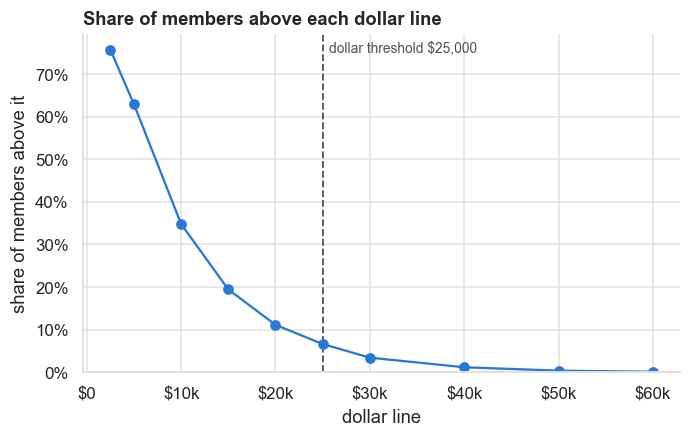


members above $50,000: 8


In [7]:
# ---------------------------------------------------------------------------
# TODO 5 — move the line.
#
# Worked example: the share of members who cost more than $5,000.
#
#     paid > 5_000              -> True/False for every member
#     (paid > 5_000).mean()     -> the share that are True (True counts as 1)
#     (paid > 5_000).sum()      -> the NUMBER that are True
#
# Your steps:
#   1. Make a list to hold your answers:   shares = []
#   2. Loop over `lines` (given below). For each one, work out the share of
#      members above it, the same way as the example, and append it.
#   3. Print each line next to its share, so you can read off $10,000.
#   4. Plot `lines` (x) against `shares` (y) with ax.plot, add dots with
#      marker="o", and call threshold_line(ax) to mark $25k.
#   5. Print the NUMBER of members above $50,000.
#
# Docs that will help:
#   - Comparing a Series to a number gives True/False
#     https://pandas.pydata.org/docs/user_guide/indexing.html#boolean-indexing
#   - Python for loops and list.append
#     https://docs.python.org/3/tutorial/controlflow.html#for-statements
#   - Axes.plot  (see the marker argument)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html
# ---------------------------------------------------------------------------

lines = [2_500, 5_000, 10_000, 15_000, 20_000, 25_000, 30_000, 40_000, 50_000, 60_000]

shares = []
for line in lines:
    shares.append((paid > line).mean())

for line, share in zip(lines, shares):
    print(f"${line:>7,}  {share:6.1%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lines, shares, marker="o", color=BLUE)
threshold_line(ax)
ax.set(title="Share of members above each dollar line",
       xlabel="dollar line", ylabel="share of members above it", ylim=(0, None))
ax.xaxis.set_major_formatter(plt.FuncFormatter(usd))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

print(f"\nmembers above $50,000: {(paid > 50_000).sum()}")

**What you should see.** A curve that starts high and drops fast. At $10k,
30–45% of members are over the line; above $50k, only a handful of *members*
(a count, not a percentage).

**Your conclusion**: what goes wrong if the line is set much lower, or much higher?

> If the line is set much lower (e.g. 10,000 dollars), about 34.8% of members count as high-cost, so the label stops picking out anyone special. If it's set much higher (e.g. 50,000 dollars), only about 8 members are high-cost, which is too few for a model to learn from or for the intervals to mean anything.

---

## 5. Do some groups have more high-cost members?

**The question.** Are older members more likely to be high-cost than younger
ones? Women more than men? One region more than another?

**Step 1: the rate.** For each group, divide the high-cost members by all the
members in that group. 20 high-cost out of 400 members is a rate of 5%.

**Step 2: why a rate on its own can fool you.** High-cost members are rare, so
each group only has a few dozen of them. With numbers that small, luck moves
the rate a lot. Two groups can look different when the gap is just chance.

Think of coin flips: 7 heads in 10 flips doesn't prove a coin is unfair, but
700 heads in 1,000 flips does. The more flips, the more you can trust the
result.

**Step 3: the 95% interval.** This is the range the group's *true* rate
probably sits in, given how many members we have. Fewer members means a wider
range. Both of these are 5%, but we're much surer about the second:

| High-cost / members | Rate | 95% interval |
|---|---|---|
| 5 / 100 | 5% | 2.2% to 11.2% |
| 50 / 1,000 | 5% | 3.8% to 6.5% |

**How to read the plot.** Each group gets one row:

```
            0%        5%        10%
Group A        |----●----|                ● = the group's rate
Group B             |------●------|       |--| = its 95% interval
                     ¦                    ¦ (dashed) = rate for everyone
```

- **The lines overlap:** you can't say the groups differ. The gap could be luck.
- **The lines don't overlap:** the difference is probably real.

Example: Group A is 20 / 400 = 5% (3.3% to 7.6%). Group B is 30 / 400 = 7.5%
(5.3% to 10.5%). B looks higher, but the ranges overlap, so you **can't** claim
a difference.

**What you'll write.** For each variable, one of two sentences:

- "*X* has a higher rate than *Y*, and their intervals don't overlap."
- "No detectable difference at this sample size."

The second one is a complete answer. It does **not** mean "there is no
difference"; it means we don't have enough members to tell.

**Why it matters.** If the data has a real gap between groups, a model trained
on it will learn that gap too. Week 6 asks whether that's fair.


age_bucket
              n  positives   rate     lo     hi
age_bucket                                     
18-29       284          9  0.032  0.017  0.059
30-39       430         18  0.042  0.027  0.065
40-49       589         41  0.070  0.052  0.093
50-59       463         37  0.080  0.059  0.108
60-64       234         28  0.120  0.084  0.168


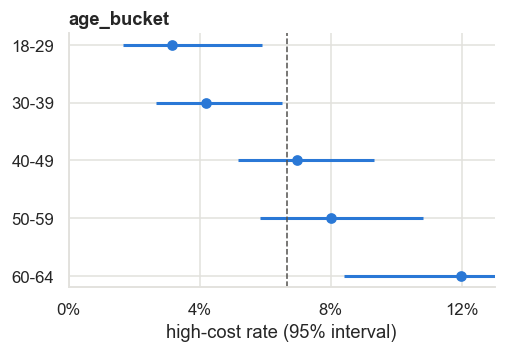


sex
        n  positives   rate     lo     hi
sex                                      
F     999         58  0.058  0.045  0.074
M    1001         75  0.075  0.060  0.093


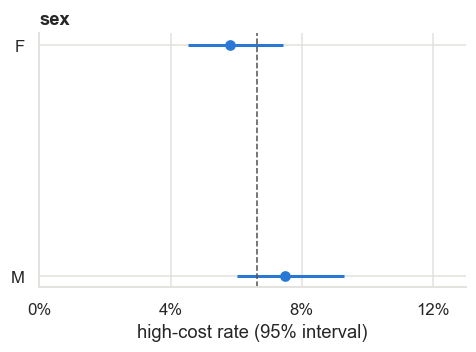


region
             n  positives   rate     lo     hi
region                                        
Midwest    365         35  0.096  0.070  0.130
Northeast  383         24  0.063  0.042  0.092
Southeast  417         22  0.053  0.035  0.079
Southwest  433         33  0.076  0.055  0.105
West       402         19  0.047  0.030  0.073


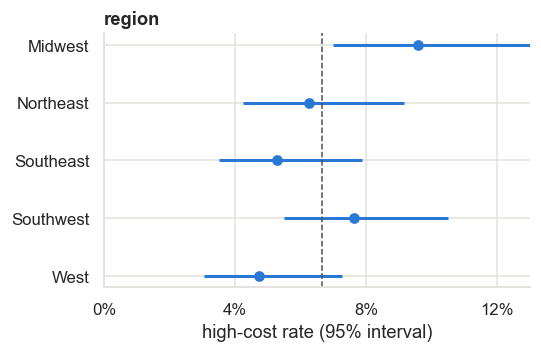

In [8]:
# ---------------------------------------------------------------------------
# TODO 6 — high-cost rate by group, with 95% intervals.
#
# Worked example: count members and high-cost members in each age bucket.
#
#     table = summary.groupby("age_bucket")["is_high_cost"].agg(n="size", positives="sum")
#
#   n         = members in the group
#   positives = high-cost members (is_high_cost is 0/1, so the sum counts the 1s)
#
# Your steps, starting with age_bucket:
#   1. Run the worked example. Then put the buckets in order:
#          table = table.reindex(AGE_ORDER)
#   2. Add a "rate" column: positives divided by n.
#   3. Add "lo" and "hi" columns with the given helper:
#          table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
#   4. print(table), then plot it with the given helper:
#          fig, ax = plt.subplots(figsize=(5, 3))
#          plot_rates(table, ax, "age_bucket")
#   5. Do the same for "sex" and "region". Skip the reindex step; those
#      groups have no natural order.
#
# Docs that will help:
#   - DataFrame.groupby
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html
#   - Adding a new column from existing ones
#     https://pandas.pydata.org/docs/getting_started/intro_tutorials/05_add_columns.html
#   - Series.reindex
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html
# ---------------------------------------------------------------------------

def rate_table(column, order=None):
    table = summary.groupby(column)["is_high_cost"].agg(n="size", positives="sum")
    if order is not None:
        table = table.reindex(order)
    table["rate"] = table["positives"] / table["n"]
    table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
    return table

for column, order in [("age_bucket", AGE_ORDER), ("sex", None), ("region", None)]:
    table = rate_table(column, order)
    print(f"\n{column}")
    print(table.round(3))
    fig, ax = plt.subplots(figsize=(5, 3))
    plot_rates(table, ax, column)
    plt.show()

**What you should see.** `sex` and `region` rates within a few points of each
other, with intervals that overlap. `age_bucket` usually rises with age, but in
some cohorts even age is too close to call.

**Your conclusion**: which variable, if any, shows a difference you can defend? For the others, write "no detectable difference at this sample size".

> Age is the only variable with a difference I can defend: 18-29 year olds have a 3.2% high-cost rate versus 12.0% for 60-64, and their intervals don't overlap. Sex: no detectable difference at this sample size. Region: no detectable difference at this sample size (Midwest 9.6% vs West 4.7% looks large, but the intervals just overlap).

---

## 6. One question for every column

The prediction is made on **January 1**. The label is only known after
**December 31**. So, for each column in `member_summary.csv`:

> **"On the day I need this prediction, do I already know this number?"**

**TODO 7: fill in the last column.** No code. Write *Yes*, *No* or
*Debatable*, and a few words of why. Look at how each column is defined, not at
how well it correlates with the label.

- **Yes:** you'd know it on January 1.
- **No:** it's the outcome, or nearly the same number as the outcome.
- **Debatable:** you'd know a version of it on January 1, but this column was
  measured over the same year as the label.

| Column | What it is | Known on day one? |
|---|---|---|
| `age_bucket` | banded age | Yes: known at enrollment |
| `sex` | recorded sex | Yes: known at enrollment |
| `region` | US region | Yes: known at enrollment |
| `total_claims` | approved claims in the year | Debatable: last year's count is known, this year's isn't |
| `medical_claims` | of those, non-pharmacy | Debatable: same as total_claims |
| `pharmacy_claims` | of those, pharmacy | Debatable: same as total_claims |
| `specialty_drug_fills` | specialty fills in the year | Debatable: last year's fills are known, this year's aren't |
| `total_billed_cents` | what providers billed | No: moves almost one-for-one with plan-paid |
| `total_allowed_cents` | what the plan allowed | No: allowed = plan-paid + out-of-pocket, so it nearly contains the label |
| `total_plan_paid_cents` | what the plan paid | No: the label is defined from this column |
| `total_oop_cents` | what the member paid | No: rises with the same spending that makes the label |
| `unique_diagnosis_codes` | distinct diagnoses seen | Debatable: last year's diagnoses are known, this year's aren't |
| `inpatient_claims` | institutional claims | Debatable: last year's count is known, this year's isn't |
| `has_specialty_drug` | any specialty fill | Debatable: a chronic specialty drug often carries over from last year |
| `is_high_cost` | the label | No: it is the outcome |

Hint: this data covers one plan year. A real system would use *last* year's
claims to predict *this* year. Which columns could you get from last year?

**Your conclusion**: which row was hardest to decide, and why?

> The hardest row was has_specialty_drug: someone on a specialty drug for a chronic condition was probably on it last year too, so it feels known on day one, but this column is measured over the same year as the label, so it is only Debatable.

`tests/test_leakage.py` fails until Weeks 3–4. That is on purpose, and this
table is what it is about.

---

## 7. Four checks before you trust a figure

In [9]:
# ---------------------------------------------------------------------------
# TODO 8a — missing or structural?
#
# Print the share of blanks in each column of claims that has any. Then
# compare those shares with the share of claims that are pharmacy.
#
# Docs that will help:
#   - DataFrame.isna
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
#   - DataFrame.mean
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html
# ---------------------------------------------------------------------------

blank_share = claims.isna().mean()
print("share of blanks, columns that have any:")
print(blank_share[blank_share > 0].round(3))

print(f"\nshare of claims that are pharmacy: {claims['is_pharmacy'].mean():.3f}")

cols = blank_share[blank_share > 0].index
print("\nblank share by claim kind:")
print(claims.groupby("is_pharmacy")[cols].agg(lambda s: s.isna().mean()).round(3))

share of blanks, columns that have any:
diagnosis_code       0.22
procedure_code       0.22
drug_name            0.78
therapeutic_class    0.78
dtype: float64

share of claims that are pharmacy: 0.220

blank share by claim kind:
             diagnosis_code  procedure_code  drug_name  therapeutic_class
is_pharmacy                                                              
False                   0.0             0.0        1.0                1.0
True                    1.0             1.0        0.0                0.0


**What you should see.** No blanks in `members` or `summary`. In `claims`, some
columns blank on about 23% of rows and others on about 77%.

**Your conclusion**: is a blank `diagnosis_code` on a pharmacy claim missing data? What would go wrong if you filled it in?

> No. A blank diagnosis_code on a pharmacy claim is structural, not missing: pharmacy claims never carry a diagnosis (100% blank), and medical claims never carry a drug name (100% blank). Filling them in, for example with the most common code, would invent diagnoses that never happened and hide the useful fact that the claim was a pharmacy fill.

In [10]:
# ---------------------------------------------------------------------------
# TODO 8b — does the money add up?
#
# Every claim should satisfy  plan_paid + out_of_pocket == allowed.
# Print the share of claims where it holds, for each claim_type.
#
# Docs that will help:
#   - Arithmetic and comparisons on columns
#     https://pandas.pydata.org/docs/user_guide/basics.html#flexible-binary-operations
#   - Series.groupby
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.groupby.html
# ---------------------------------------------------------------------------

holds = claims["plan_paid_cents"] + claims["out_of_pocket_cents"] == claims["allowed_cents"]

print("share of claims where plan_paid + out_of_pocket == allowed:")
print(holds.groupby(claims["claim_type"]).mean().round(3))

share of claims where plan_paid + out_of_pocket == allowed:
claim_type
Institutional    0.916
Pharmacy         0.000
Professional     0.920
dtype: float64


**What you should see.** The identity holds for most medical claims and for
**none** of the pharmacy claims.

**Your conclusion**: the identity fails on some claims. Why does that matter before you build features from these columns?

> The identity holds for about 92% of medical claims and 0% of pharmacy claims. That matters because I can't assume the money columns are consistent with each other: if I built a feature like "share the member paid" or derived one amount from the others, it would be wrong for every pharmacy claim and some medical ones. I need to know why each column is what it is before using it.

In [11]:
# ---------------------------------------------------------------------------
# TODO 8c — do the counts match?
#
# For each member, does summary's total_claims equal (i) ALL their claims,
# or (ii) only their APPROVED claims? Print the share of members that match
# each. Members with no claims at all should count as 0, not be dropped.
#
# Docs that will help:
#   - DataFrameGroupBy.size
#     https://pandas.pydata.org/docs/reference/api/pandas.api.typing.DataFrameGroupBy.size.html
#   - DataFrame.set_index
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html
#   - Series.reindex  (see fill_value)
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html
# ---------------------------------------------------------------------------

member_ids = summary["member_id"]

all_counts = claims.groupby("member_id").size().reindex(member_ids, fill_value=0)
approved = claims[claims["adjudication_status"] == "approved"]
approved_counts = approved.groupby("member_id").size().reindex(member_ids, fill_value=0)

reported = summary.set_index("member_id")["total_claims"]

print(f"matches ALL claims:      {(reported == all_counts).mean():.1%}")
print(f"matches APPROVED claims: {(reported == approved_counts).mean():.1%}")

print("\nclaims by adjudication_status:")
print(claims["adjudication_status"].value_counts())

matches ALL claims:      54.0%
matches APPROVED claims: 100.0%

claims by adjudication_status:
adjudication_status
approved    20106
denied       1313
Name: count, dtype: int64


**What you should see.** One of the two matches for 100% of members.

**Your conclusion**: which claims does `member_summary.csv` count, and why?

> member_summary.csv counts only approved claims (100% match, versus 54% when counting all claims). The 1,313 denied claims are left out because the plan paid nothing on them, so they are not part of the member's cost. Any feature I build from claims.csv has to apply the same approved-only filter, or it won't match the summary.

service_date
1     1797
2     1660
3     1867
4     1721
5     1859
6     1824
7     1821
8     1863
9     1731
10    1763
11    1727
12    1786
Name: count, dtype: int64


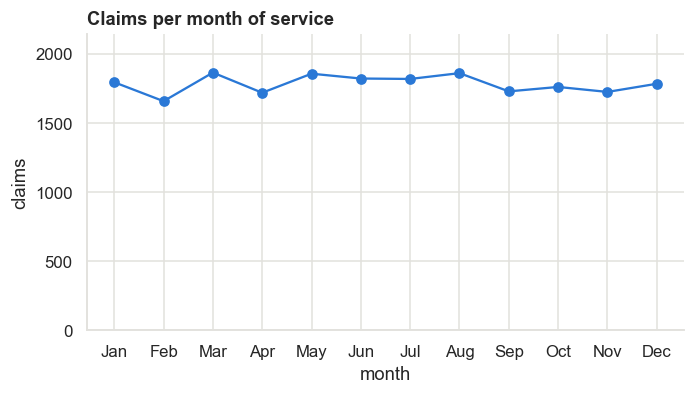

In [12]:
# ---------------------------------------------------------------------------
# TODO 8d — any time pattern?
#
# Plot the number of claims in each month of service_date, as a line.
# Start the y axis at 0 so small wiggles don't look big.
#
# Docs that will help:
#   - pandas.to_datetime
#     https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
#   - Series.dt.month
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.month.html
#   - Series.value_counts and Series.sort_index
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html
#   - Axes.set  (ylim=...)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set.html
# ---------------------------------------------------------------------------

months = pd.to_datetime(claims["service_date"]).dt.month
per_month = months.value_counts().sort_index()
print(per_month)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(per_month.index, per_month.values, marker="o", color=BLUE)
ax.set(title="Claims per month of service", xlabel="month", ylabel="claims",
       ylim=(0, per_month.max() * 1.15))
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.show()

**What you should see.** A roughly flat line.

**Your conclusion**: is there a seasonal pattern? What does that mean for features like "month of first claim"?

> No seasonal pattern: claims per month stay between about 1,660 and 1,870, and February is lowest only because it is shorter. So a feature like "month of first claim" would carry almost no signal here, and it would also be leaky: on January 1 I don't yet know when this year's first claim will happen.

---

## 8. What to carry into Week 3

Fill in your numbers. These are the start of your Week 8 slides.

**The prediction target**

| | |
|---|---|
| Label column | is_high_cost |
| It is 1 when | total_plan_paid_cents is over 25,000 dollars |
| Measured over | one plan year (January 1 to December 31) |
| Predicted on | January 1, before any of that year's claims happen |
| Kind of problem | classification |

**Your cohort**

| Finding | Your number |
|---|---|
| Claims rows per member | 10.7 |
| Median vs. mean plan-paid | 7,012 dollars vs. 9,393 dollars |
| Share of spend held by the top 5% | 19.6% |
| Prevalence at 25k dollars | 6.7% |
| Accuracy of predicting nobody | 93.3% |
| Columns marked Yes / Debatable / No | 3 / 7 / 5 |

## Before you open your PR

- [ ] `pytest tests/test_data.py -v` — nine passing
- [ ] Every `______` is filled in
- [ ] **Kernel → Restart & Run All** works top to bottom
- [ ] The seed printed in section 0 is the one you were assigned
- [ ] Nothing in `data/` is staged — `git status` should not list it

Then commit the notebook, open a PR, and review your partner's. Their seed is
different, so ask how they got their numbers rather than comparing values.